# Exploratory Data Analysis (EDA) – Telco Customer Churn

**Objective:** Explore customer demographics, services, account information, and churn patterns to identify factors associated with customer churn.

**Dataset:** `WA_Fn-UseC_-Telco-Customer-Churn.csv`

## EDA workflow
1. Load and understand the data
2. Inspect columns and data types
3. Check data quality (missing values, duplicates, invalid values)
4. Perform univariate analysis
5. Perform bivariate analysis
6. Perform multivariate analysis
7. Detect potential outliers
8. Summarize business insights and modeling considerations


## 1. Import libraries

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

print("Libraries imported successfully.")

Libraries imported successfully.


## 2. Load the dataset

In [2]:
# Update this path if your CSV file is stored elsewhere.
DATA_PATH = "..\\data\\raw\\WA_Fn-UseC_-Telco-Customer-Churn.csv"

df = pd.read_csv(DATA_PATH)

print("Dataset loaded successfully.")
print("Shape:", df.shape)
display(df.head())

Dataset loaded successfully.
Shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## 3. Initial data understanding

In [3]:
# First and last records
display(df.head())
display(df.tail())

# Dataset dimensions
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

# Column names
print(df.columns.tolist())

# Data types and non-null counts
df.info()


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
7038,6840-RESVB,Male,0,Yes,Yes,24,Yes,Yes,DSL,Yes,No,Yes,Yes,Yes,Yes,One year,Yes,Mailed check,84.80,1990.5,No
7039,2234-XADUH,Female,0,Yes,Yes,72,Yes,Yes,Fiber optic,No,Yes,Yes,No,Yes,Yes,One year,Yes,Credit card (automatic),103.20,7362.9,No
7040,4801-JZAZL,Female,0,Yes,Yes,11,No,No phone service,DSL,Yes,No,No,No,No,No,Month-to-month,Yes,Electronic check,29.60,346.45,No
7041,8361-LTMKD,Male,1,Yes,No,4,Yes,Yes,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Mailed check,74.40,306.6,Yes
7042,3186-AJIEK,Male,0,No,No,66,Yes,No,Fiber optic,Yes,No,Yes,Yes,Yes,Yes,Two year,Yes,Bank transfer (automatic),105.65,6844.5,No


Rows: 7043
Columns: 21
['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']
<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   s

In [4]:
# Descriptive statistics for all columns
display(df.describe(include="all").T)

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
customerID,7043,7043,7590-VHVEG,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
gender,7043,2,Male,3555,NaN,NaN,NaN,NaN,NaN,NaN,NaN
SeniorCitizen,7043.0,NaN,NaN,NaN,0.162147,0.368612,0.0,0.0,0.0,0.0,1.0
Partner,7043,2,No,3641,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Dependents,7043,2,No,4933,NaN,NaN,NaN,NaN,NaN,NaN,NaN
tenure,7043.0,NaN,NaN,NaN,32.371149,24.559481,0.0,9.0,29.0,55.0,72.0
PhoneService,7043,2,Yes,6361,NaN,NaN,NaN,NaN,NaN,NaN,NaN
MultipleLines,7043,3,No,3390,NaN,NaN,NaN,NaN,NaN,NaN,NaN
InternetService,7043,3,Fiber optic,3096,NaN,NaN,NaN,NaN,NaN,NaN,NaN
OnlineSecurity,7043,3,No,3498,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 4. Column classification

The dataset contains:
- **Identifier:** `customerID`
- **Target:** `Churn`
- **Numerical:** `tenure`, `MonthlyCharges`, `TotalCharges`
- **Binary numeric categorical:** `SeniorCitizen`
- **Categorical:** remaining service, demographic, and account columns

The classification is based on the meaning of each field, not only its pandas dtype.

In [5]:
identifier_cols = ["customerID"]
target_col = "Churn"

numeric_cols = ["tenure", "MonthlyCharges", "TotalCharges"]
binary_numeric_cols = ["SeniorCitizen"]

categorical_cols = [
    col for col in df.columns
    if col not in identifier_cols + [target_col] + numeric_cols + binary_numeric_cols
]

print("Identifier:", identifier_cols)
print("Target:", target_col)
print("Numerical:", numeric_cols)
print("Binary numeric categorical:", binary_numeric_cols)
print("Categorical:", categorical_cols)

Identifier: ['customerID']
Target: Churn
Numerical: ['tenure', 'MonthlyCharges', 'TotalCharges']
Binary numeric categorical: ['SeniorCitizen']
Categorical: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']


## 5. Data quality checks

### 5.1 Missing values and blank strings

In [6]:
# Count actual null values
print("Null values before cleaning:")
display(df.isna().sum().sort_values(ascending=False))

# Check whitespace-only strings in object columns
blank_counts = {}
for col in df.select_dtypes(include="object").columns:
    blank_counts[col] = df[col].astype(str).str.strip().eq("").sum()

print("Whitespace-only values:")
display(pd.Series(blank_counts).sort_values(ascending=False))

Null values before cleaning:


customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

Whitespace-only values:


TotalCharges        11
customerID           0
gender               0
Partner              0
PhoneService         0
Dependents           0
InternetService      0
OnlineSecurity       0
OnlineBackup         0
MultipleLines        0
DeviceProtection     0
TechSupport          0
StreamingMovies      0
StreamingTV          0
Contract             0
PaperlessBilling     0
PaymentMethod        0
Churn                0
dtype: int64

### 5.2 Convert `TotalCharges` to numeric

In [7]:
# In this dataset, some TotalCharges entries contain whitespace.
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"].astype(str).str.strip(),
    errors="coerce"
)

print("Missing values after conversion:")
display(df.isna().sum().sort_values(ascending=False))

print("Rows with missing TotalCharges:")
display(df.loc[df["TotalCharges"].isna(), ["customerID", "tenure", "MonthlyCharges", "TotalCharges"]])

Missing values after conversion:


TotalCharges        11
gender               0
SeniorCitizen        0
Partner              0
customerID           0
Dependents           0
tenure               0
MultipleLines        0
PhoneService         0
OnlineSecurity       0
OnlineBackup         0
DeviceProtection     0
InternetService      0
TechSupport          0
StreamingTV          0
Contract             0
StreamingMovies      0
PaperlessBilling     0
PaymentMethod        0
MonthlyCharges       0
Churn                0
dtype: int64

Rows with missing TotalCharges:


,customerID,tenure,MonthlyCharges,TotalCharges
488,4472-LVYGI,0,52.55,NaN
753,3115-CZMZD,0,20.25,NaN
936,5709-LVOEQ,0,80.85,NaN
1082,4367-NUYAO,0,25.75,NaN
1340,1371-DWPAZ,0,56.05,NaN
3331,7644-OMVMY,0,19.85,NaN
3826,3213-VVOLG,0,25.35,NaN
4380,2520-SGTTA,0,20.00,NaN
5218,2923-ARZLG,0,19.70,NaN
6670,4075-WKNIU,0,73.35,NaN


**Decision:** The blank `TotalCharges` values occur for customers with zero tenure in the commonly distributed version of this dataset. Do not automatically replace them with the mean. Inspect the records and decide whether to retain them, impute them with a justified value, or exclude them for a particular analysis/modeling task.

In [8]:
# Verify whether missing TotalCharges rows have zero tenure
if df["TotalCharges"].isna().any():
    display(df.loc[df["TotalCharges"].isna(), "tenure"].value_counts(dropna=False))

tenure
0    11
Name: count, dtype: int64

### 5.3 Duplicate records and identifier checks

In [9]:
print("Duplicate complete rows:", df.duplicated().sum())
print("Duplicate customer IDs:", df["customerID"].duplicated().sum())

# Inspect duplicate IDs if any
duplicate_ids = df[df["customerID"].duplicated(keep=False)].sort_values("customerID")
display(duplicate_ids.head(20))

Duplicate complete rows: 0
Duplicate customer IDs: 0


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn


### 5.4 Data types and valid category values

In [10]:
display(df.dtypes)

customerID              str
gender                  str
SeniorCitizen         int64
Partner                 str
Dependents              str
tenure                int64
PhoneService            str
MultipleLines           str
InternetService         str
OnlineSecurity          str
OnlineBackup            str
DeviceProtection        str
TechSupport             str
StreamingTV             str
StreamingMovies         str
Contract                str
PaperlessBilling        str
PaymentMethod           str
MonthlyCharges      float64
TotalCharges        float64
Churn                   str
dtype: object

In [11]:
for col in categorical_cols + [target_col]:
    print(f"{col}: {sorted(df[col].dropna().astype(str).unique())}")

gender: ['Female', 'Male']
Partner: ['No', 'Yes']
Dependents: ['No', 'Yes']
PhoneService: ['No', 'Yes']
MultipleLines: ['No', 'No phone service', 'Yes']
InternetService: ['DSL', 'Fiber optic', 'No']
OnlineSecurity: ['No', 'No internet service', 'Yes']
OnlineBackup: ['No', 'No internet service', 'Yes']
DeviceProtection: ['No', 'No internet service', 'Yes']
TechSupport: ['No', 'No internet service', 'Yes']
StreamingTV: ['No', 'No internet service', 'Yes']
StreamingMovies: ['No', 'No internet service', 'Yes']
Contract: ['Month-to-month', 'One year', 'Two year']
PaperlessBilling: ['No', 'Yes']
PaymentMethod: ['Bank transfer (automatic)', 'Credit card (automatic)', 'Electronic check', 'Mailed check']
Churn: ['No', 'Yes']


## 6. Univariate analysis

### 6.1 Numerical summary statistics

In [12]:
display(df[numeric_cols].describe().T)

# Additional statistics
summary = pd.DataFrame({
    "mean": df[numeric_cols].mean(),
    "median": df[numeric_cols].median(),
    "mode": df[numeric_cols].mode().iloc[0],
    "variance": df[numeric_cols].var(),
    "std_dev": df[numeric_cols].std(),
    "skewness": df[numeric_cols].skew(),
    "kurtosis": df[numeric_cols].kurt()
})
display(summary)

,count,mean,std,min,25%,50%,75%,max
tenure,7043.0,32.371149,24.559481,0.00,9.00,29.000,55.0000,72.00
MonthlyCharges,7043.0,64.761692,30.090047,18.25,35.50,70.350,89.8500,118.75
TotalCharges,7032.0,2283.300441,2266.771362,18.80,401.45,1397.475,3794.7375,8684.80


,mean,median,mode,variance,std_dev,skewness,kurtosis
tenure,32.371149,29.000,1.00,6.031681e+02,24.559481,0.239540,-1.387372
MonthlyCharges,64.761692,70.350,20.05,9.054109e+02,30.090047,-0.220524,-1.257260
TotalCharges,2283.300441,1397.475,20.20,5.138252e+06,2266.771362,0.961642,-0.231799


### 6.2 Numerical distributions

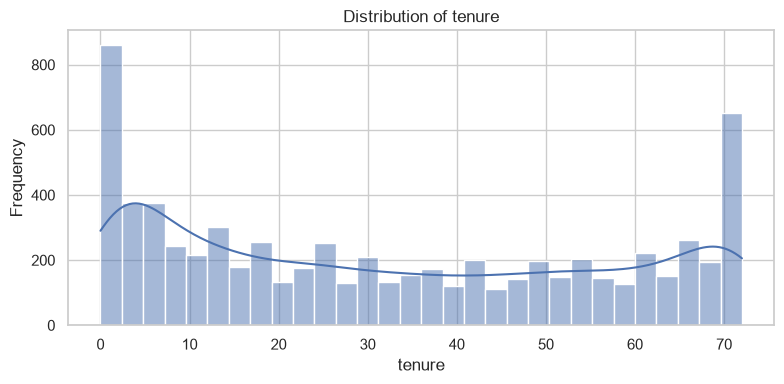

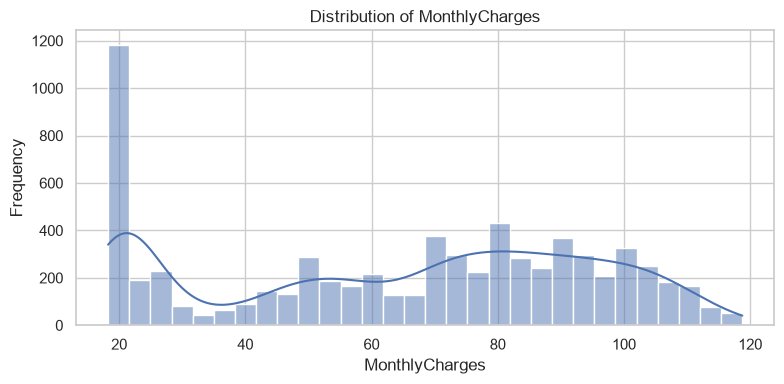

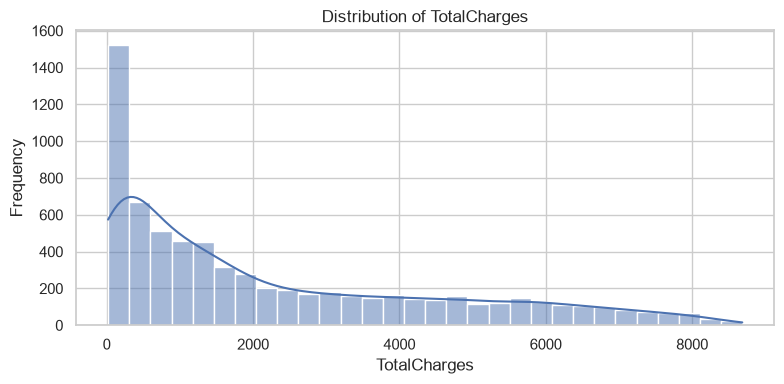

In [13]:
for col in numeric_cols:
    plt.figure(figsize=(8, 4))
    sns.histplot(data=df, x=col, kde=True, bins=30)
    plt.title(f"Distribution of {col}")
    plt.xlabel(col)
    plt.ylabel("Frequency")
    plt.tight_layout()
    plt.show()

### 6.3 Categorical frequency distributions

,count
gender,
Male,3555
Female,3488


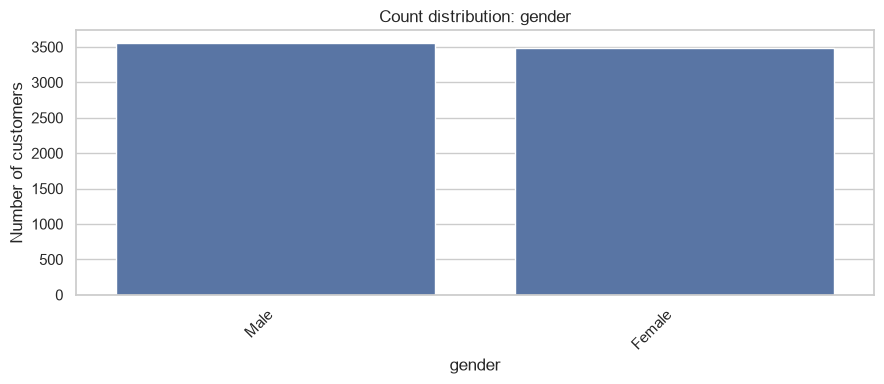

,count
Partner,
No,3641
Yes,3402


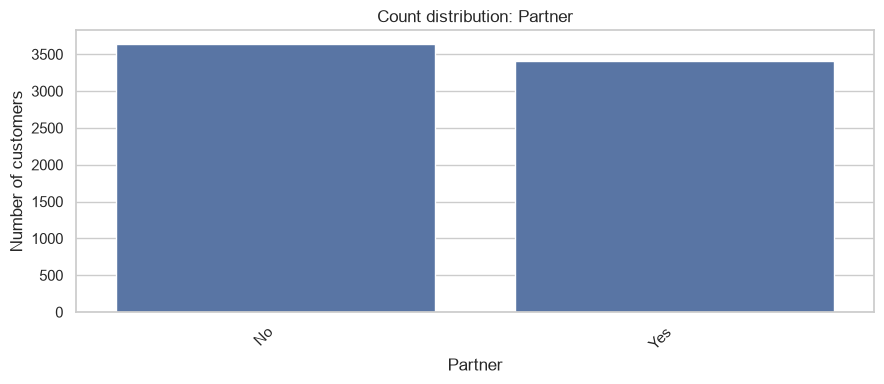

,count
Dependents,
No,4933
Yes,2110


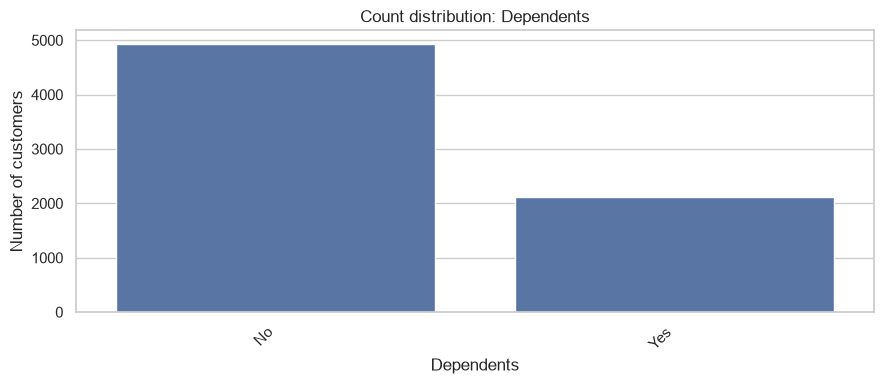

,count
PhoneService,
Yes,6361
No,682


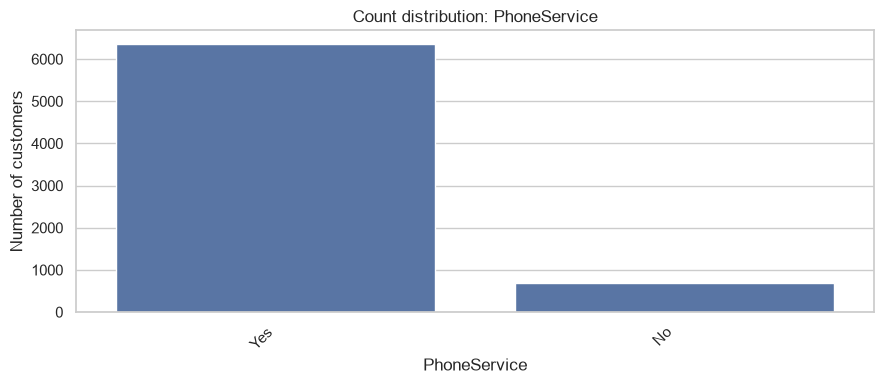

,count
MultipleLines,
No,3390
Yes,2971
No phone service,682


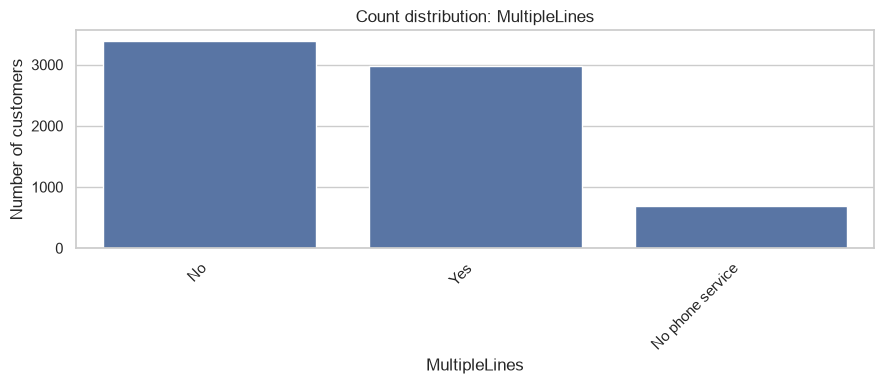

,count
InternetService,
Fiber optic,3096
DSL,2421
No,1526


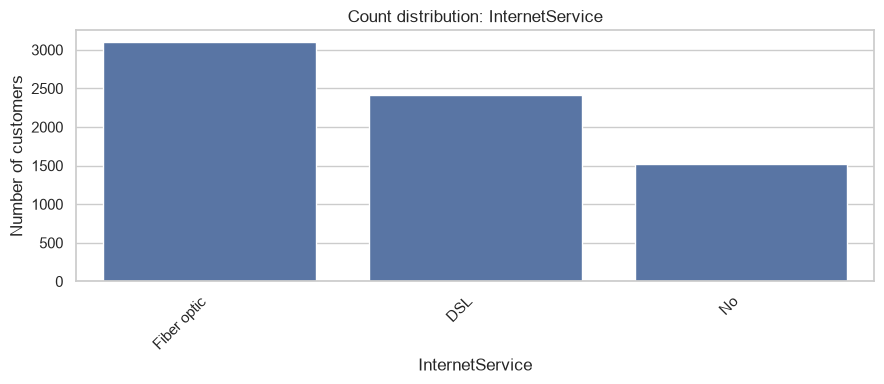

,count
OnlineSecurity,
No,3498
Yes,2019
No internet service,1526


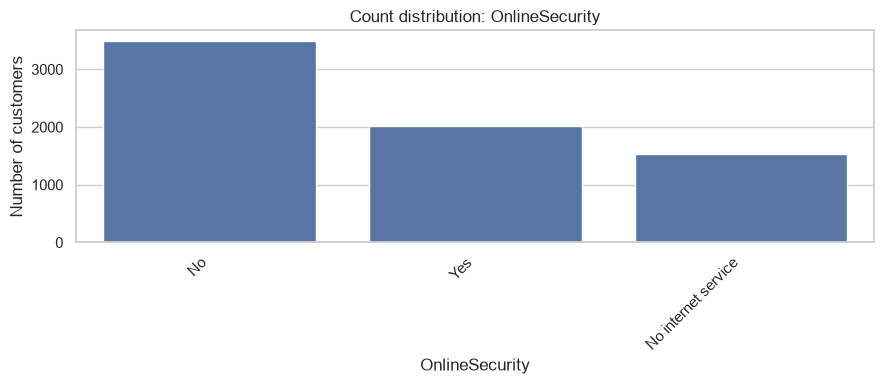

,count
OnlineBackup,
No,3088
Yes,2429
No internet service,1526


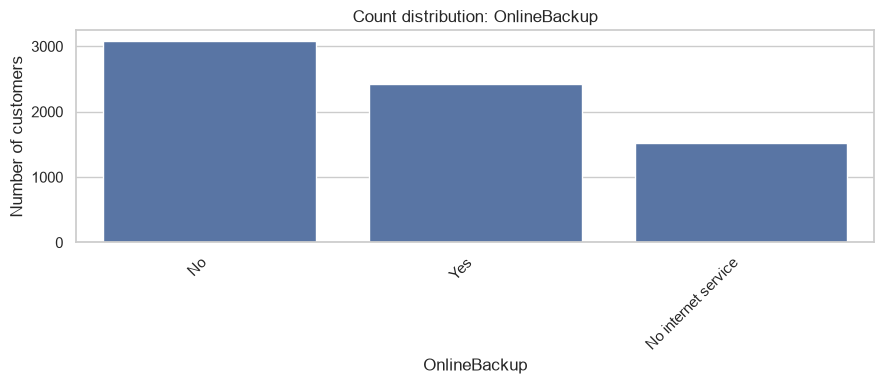

,count
DeviceProtection,
No,3095
Yes,2422
No internet service,1526


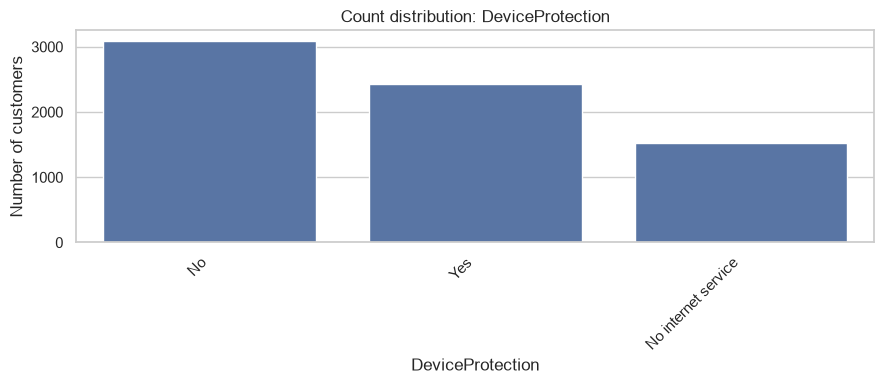

,count
TechSupport,
No,3473
Yes,2044
No internet service,1526


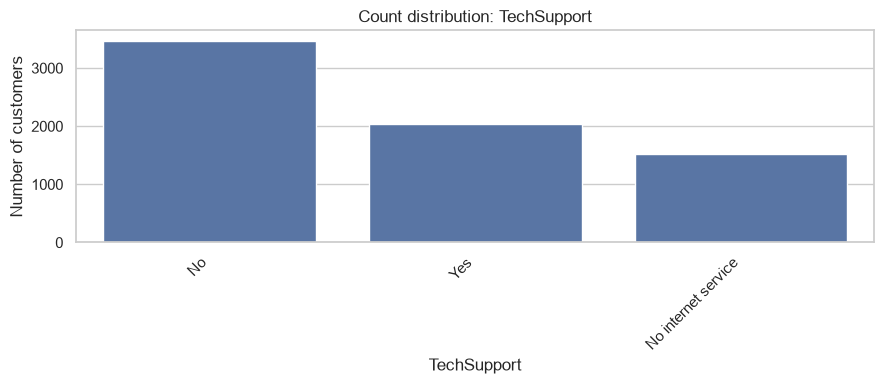

,count
StreamingTV,
No,2810
Yes,2707
No internet service,1526


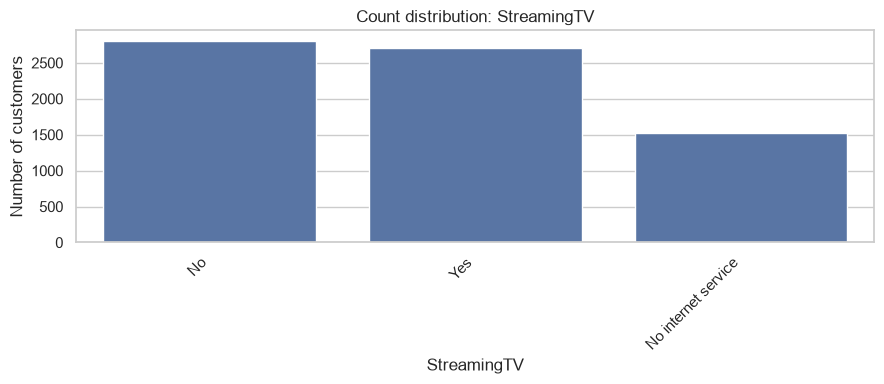

,count
StreamingMovies,
No,2785
Yes,2732
No internet service,1526


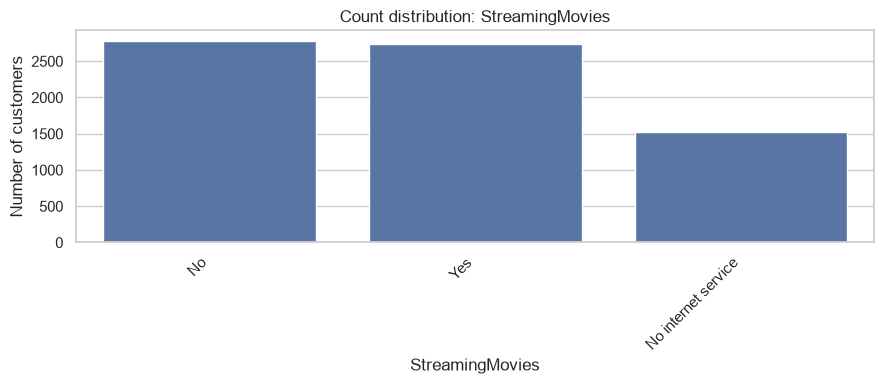

,count
Contract,
Month-to-month,3875
Two year,1695
One year,1473


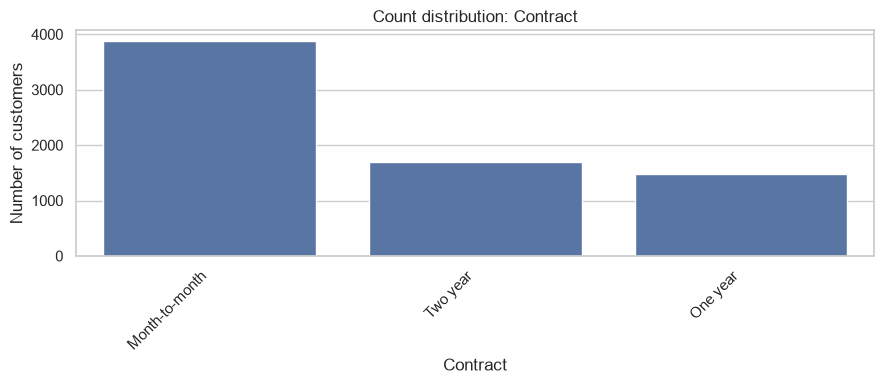

,count
PaperlessBilling,
Yes,4171
No,2872


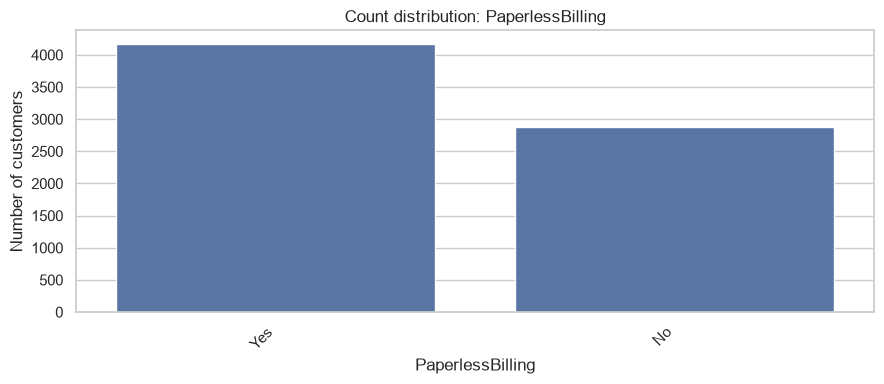

,count
PaymentMethod,
Electronic check,2365
Mailed check,1612
Bank transfer (automatic),1544
Credit card (automatic),1522


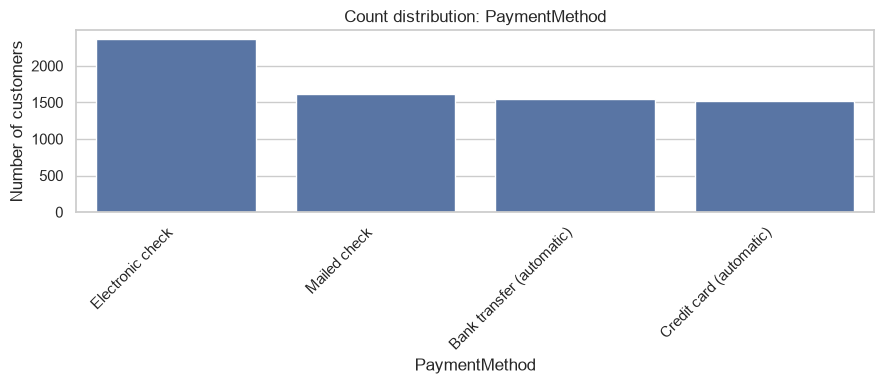

,count
Churn,
No,5174
Yes,1869


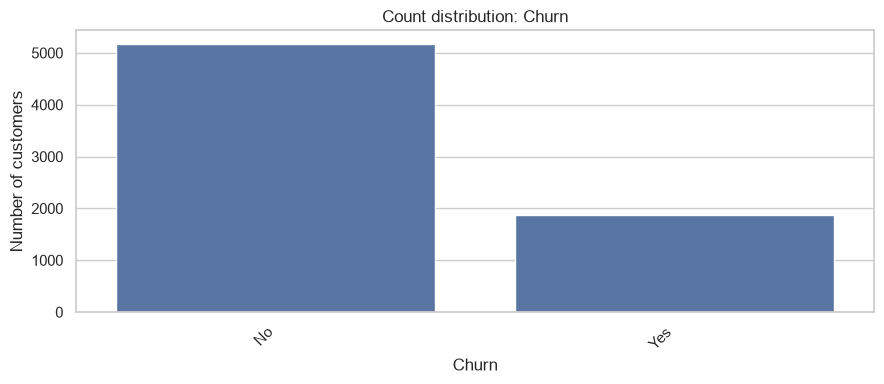

In [14]:
for col in categorical_cols + [target_col]:
    counts = df[col].value_counts(dropna=False)
    display(counts.rename_axis(col).to_frame("count"))

    plt.figure(figsize=(9, 4))
    order = df[col].value_counts().index
    sns.countplot(data=df, x=col, order=order)
    plt.title(f"Count distribution: {col}")
    plt.xlabel(col)
    plt.ylabel("Number of customers")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()

## 7. Target variable analysis – Churn

,customers,percentage
Churn,,
No,5174,73.46
Yes,1869,26.54


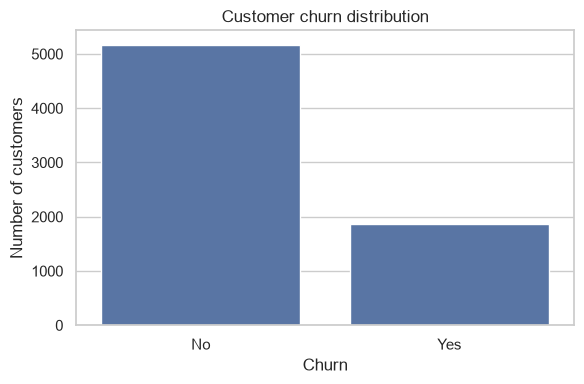

In [15]:
churn_counts = df["Churn"].value_counts(dropna=False)
churn_percent = df["Churn"].value_counts(normalize=True, dropna=False).mul(100)

churn_summary = pd.DataFrame({
    "customers": churn_counts,
    "percentage": churn_percent.round(2)
})
display(churn_summary)

plt.figure(figsize=(6, 4))
sns.countplot(data=df, x="Churn", order=["No", "Yes"])
plt.title("Customer churn distribution")
plt.xlabel("Churn")
plt.ylabel("Number of customers")
plt.tight_layout()
plt.show()

## 8. Bivariate analysis

### 8.1 Categorical features versus churn

Churn percentage by gender:


Churn,No,Yes
gender,,
Female,73.08,26.92
Male,73.84,26.16


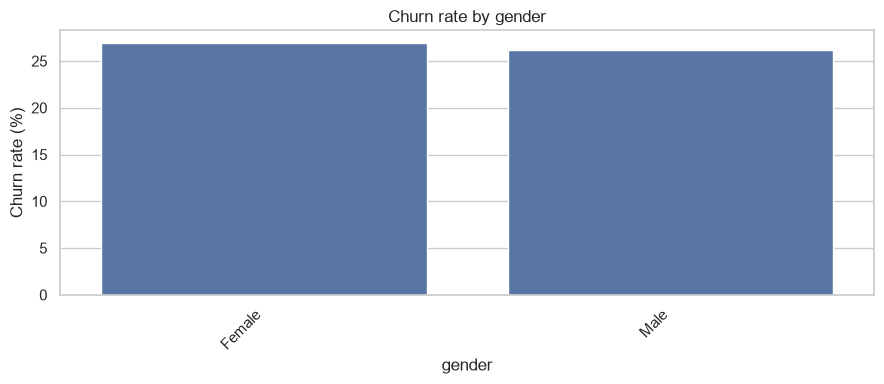

Churn percentage by Partner:


Churn,No,Yes
Partner,,
No,67.04,32.96
Yes,80.34,19.66


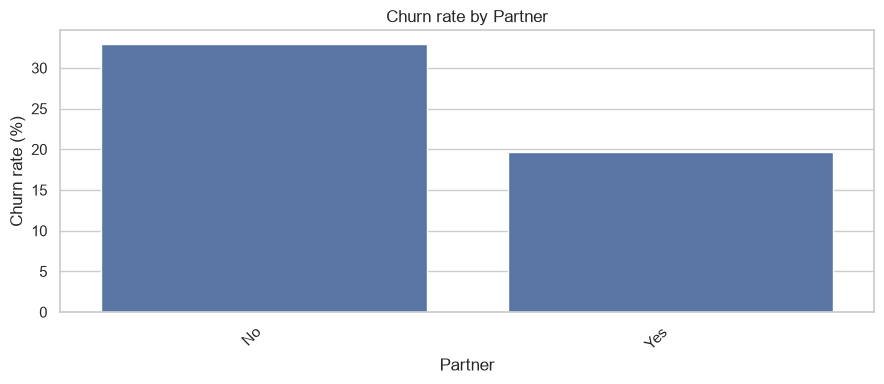

Churn percentage by Dependents:


Churn,No,Yes
Dependents,,
No,68.72,31.28
Yes,84.55,15.45


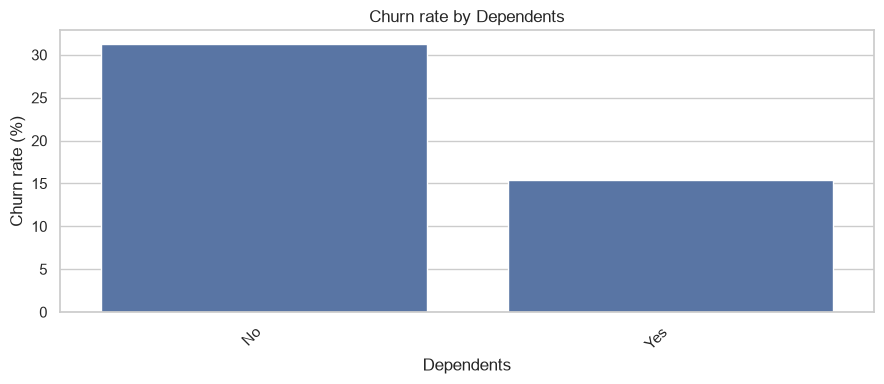

Churn percentage by PhoneService:


Churn,No,Yes
PhoneService,,
No,75.07,24.93
Yes,73.29,26.71


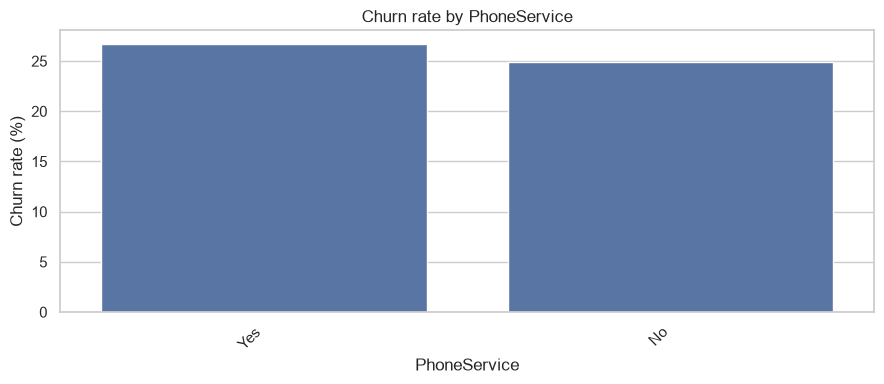

Churn percentage by MultipleLines:


Churn,No,Yes
MultipleLines,,
No,74.96,25.04
No phone service,75.07,24.93
Yes,71.39,28.61


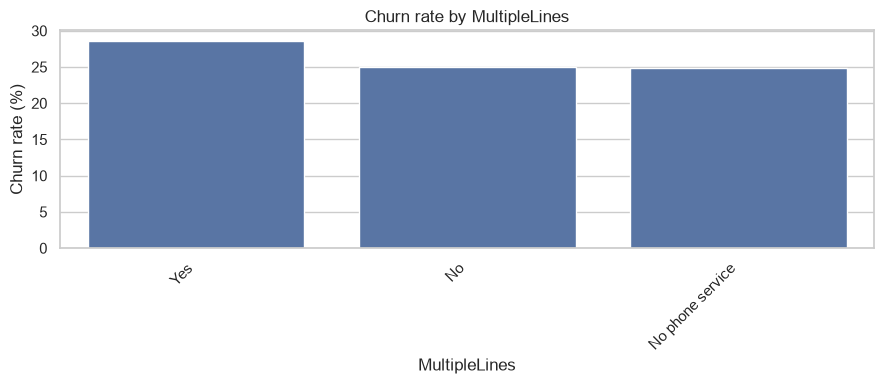

Churn percentage by InternetService:


Churn,No,Yes
InternetService,,
DSL,81.04,18.96
Fiber optic,58.11,41.89
No,92.60,7.40


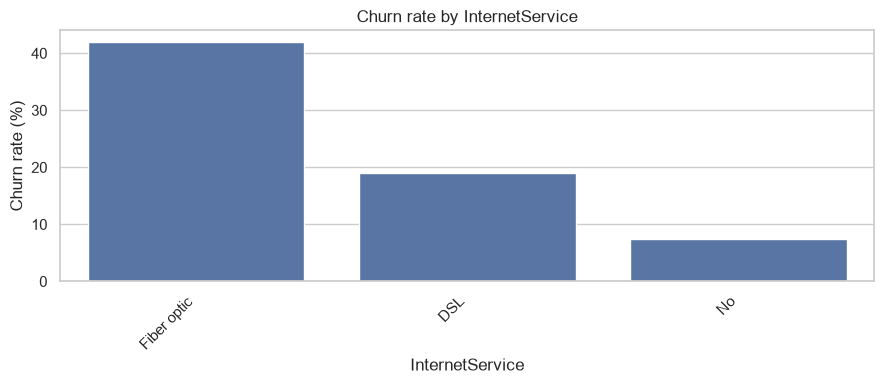

Churn percentage by OnlineSecurity:


Churn,No,Yes
OnlineSecurity,,
No,58.23,41.77
No internet service,92.60,7.40
Yes,85.39,14.61


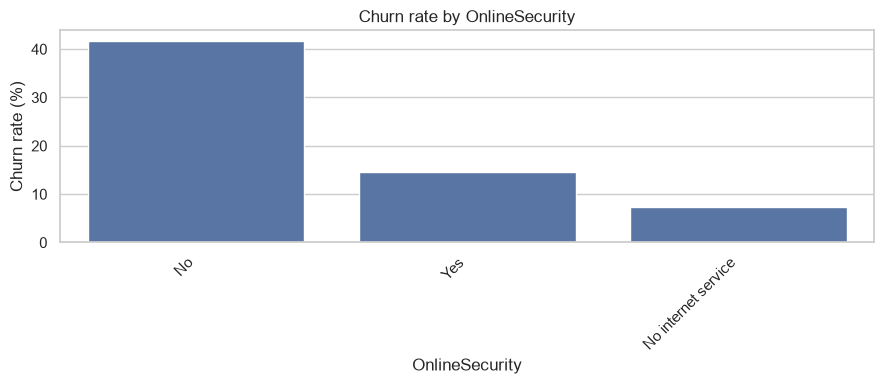

Churn percentage by OnlineBackup:


Churn,No,Yes
OnlineBackup,,
No,60.07,39.93
No internet service,92.60,7.40
Yes,78.47,21.53


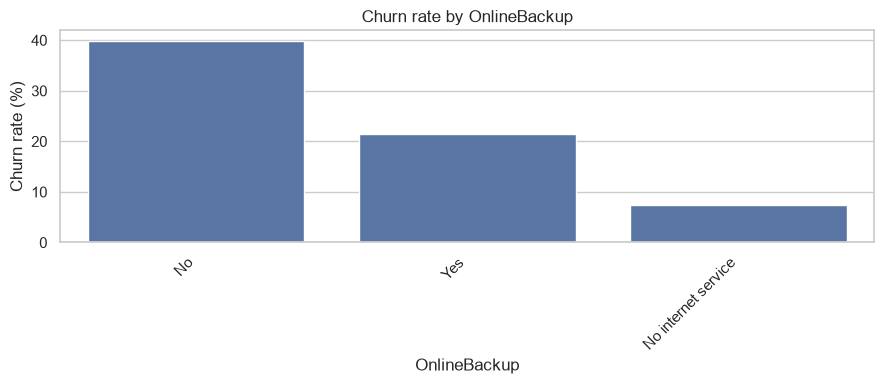

Churn percentage by DeviceProtection:


Churn,No,Yes
DeviceProtection,,
No,60.87,39.13
No internet service,92.60,7.40
Yes,77.50,22.50


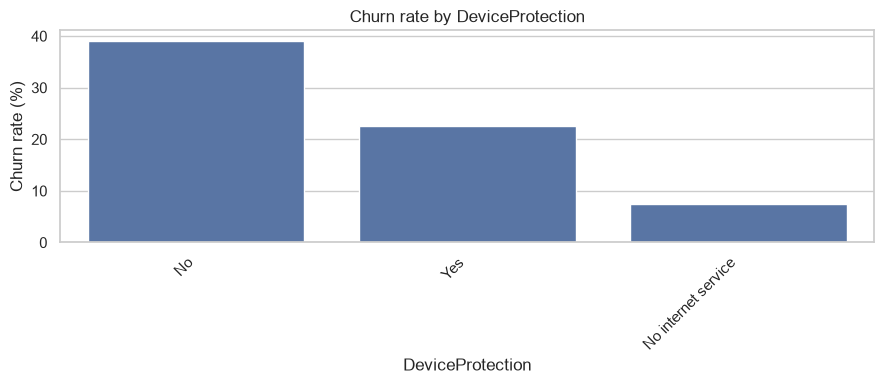

Churn percentage by TechSupport:


Churn,No,Yes
TechSupport,,
No,58.36,41.64
No internet service,92.60,7.40
Yes,84.83,15.17


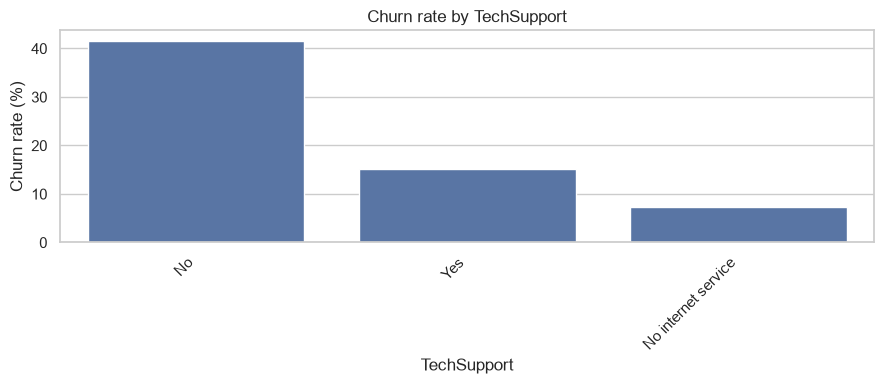

Churn percentage by StreamingTV:


Churn,No,Yes
StreamingTV,,
No,66.48,33.52
No internet service,92.60,7.40
Yes,69.93,30.07


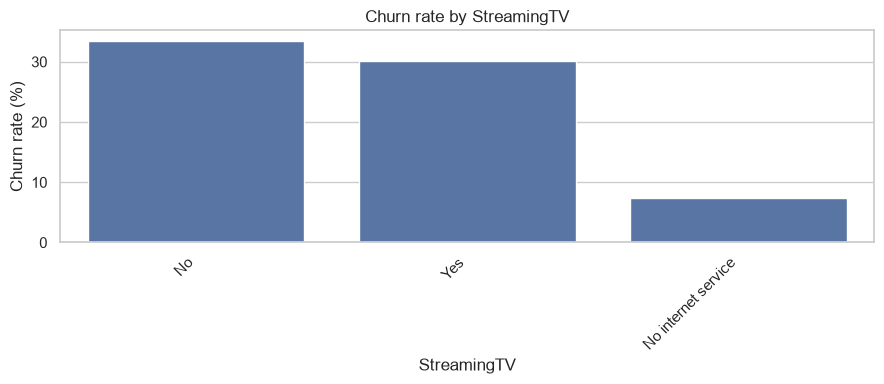

Churn percentage by StreamingMovies:


Churn,No,Yes
StreamingMovies,,
No,66.32,33.68
No internet service,92.60,7.40
Yes,70.06,29.94


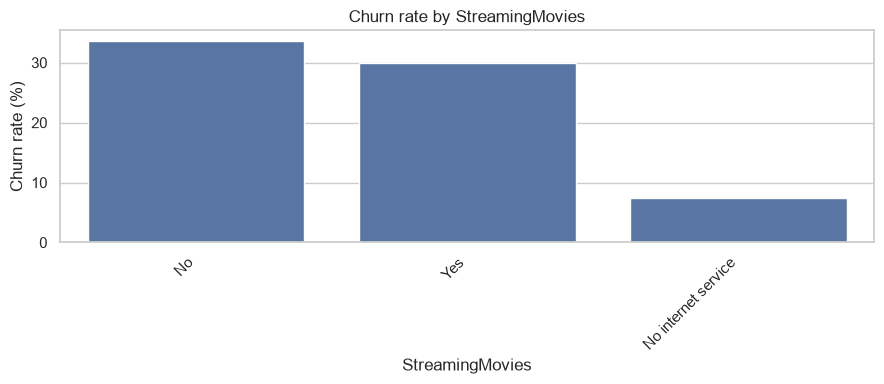

Churn percentage by Contract:


Churn,No,Yes
Contract,,
Month-to-month,57.29,42.71
One year,88.73,11.27
Two year,97.17,2.83


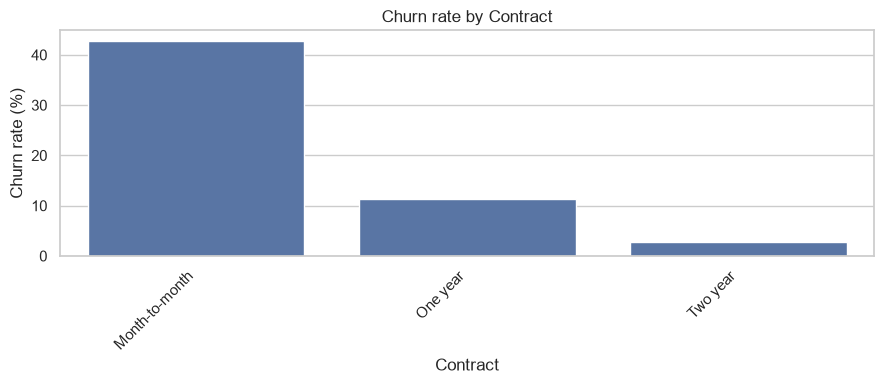

Churn percentage by PaperlessBilling:


Churn,No,Yes
PaperlessBilling,,
No,83.67,16.33
Yes,66.43,33.57


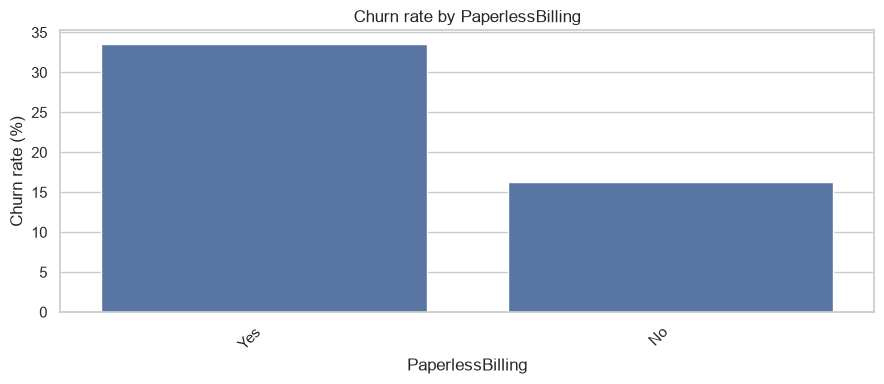

Churn percentage by PaymentMethod:


Churn,No,Yes
PaymentMethod,,
Bank transfer (automatic),83.29,16.71
Credit card (automatic),84.76,15.24
Electronic check,54.71,45.29
Mailed check,80.89,19.11


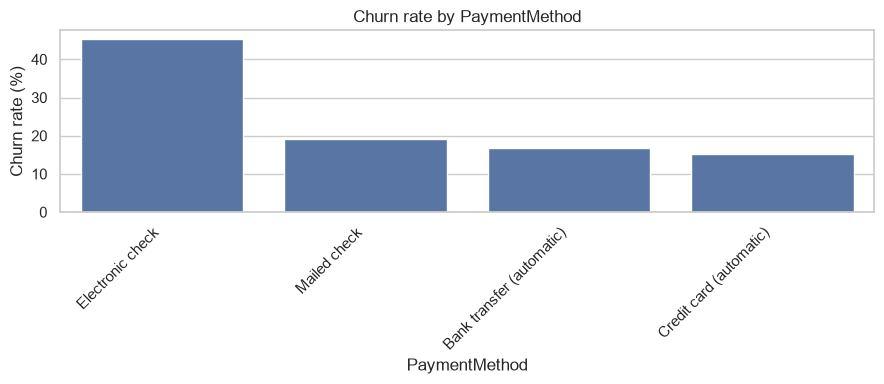

Churn percentage by SeniorCitizen:


Churn,No,Yes
SeniorCitizen,,
0,76.39,23.61
1,58.32,41.68


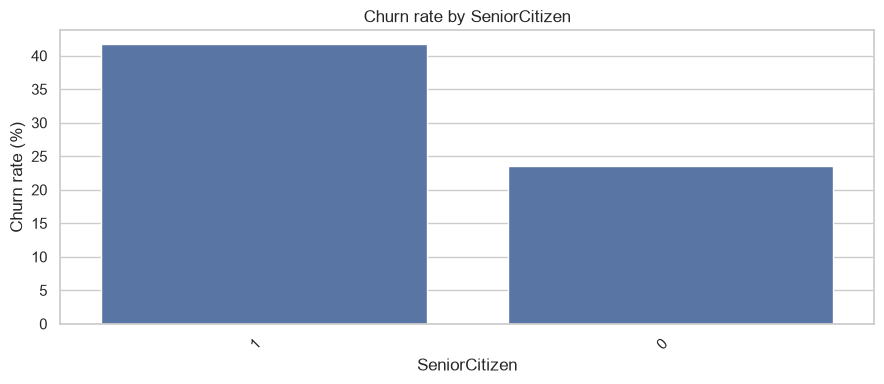

In [16]:
# Calculate churn rate within each category (row-wise percentage)
for col in categorical_cols + binary_numeric_cols:
    rate = pd.crosstab(df[col], df["Churn"], normalize="index").mul(100)
    print(f"Churn percentage by {col}:")
    display(rate.round(2))

    if "Yes" in rate.columns:
        plot_data = rate["Yes"].sort_values(ascending=False)
        plt.figure(figsize=(9, 4))
        sns.barplot(x=plot_data.index.astype(str), y=plot_data.values)
        plt.title(f"Churn rate by {col}")
        plt.xlabel(col)
        plt.ylabel("Churn rate (%)")
        plt.xticks(rotation=45, ha="right")
        plt.tight_layout()
        plt.show()

### 8.2 Numerical features versus churn

tenure                      MonthlyCharges                       \
       count   mean median    std          count   mean median    std   
Churn                                                                   
No      5174  37.57   38.0  24.11           5174  61.27  64.43  31.09   
Yes     1869  17.98   10.0  19.53           1869  74.44  79.65  24.67   

      TotalCharges                             
             count     mean   median      std  
Churn                                          
No            5163  2555.34  1683.60  2329.46  
Yes           1869  1531.80   703.55  1890.82

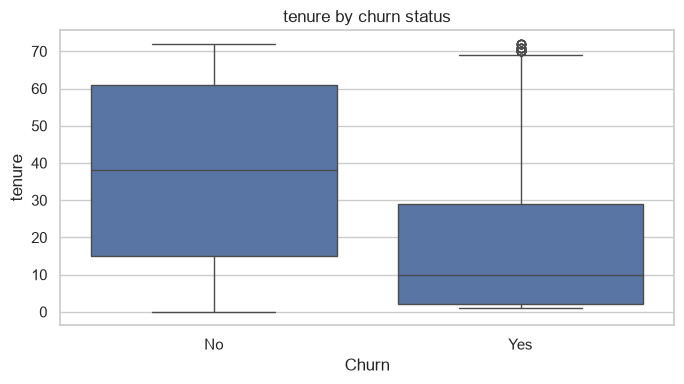

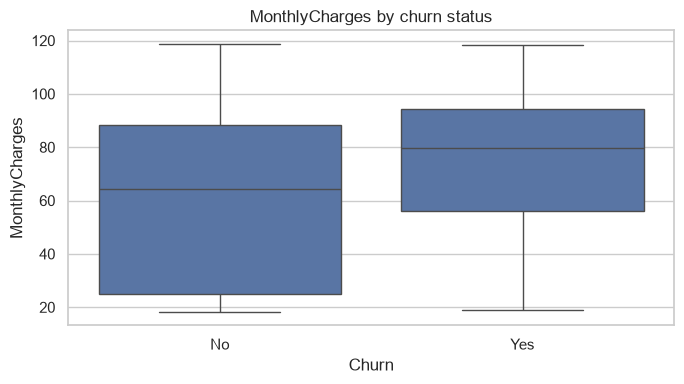

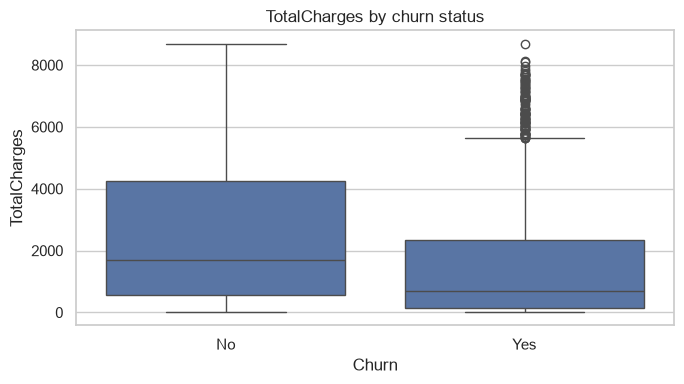

In [17]:
display(
    df.groupby("Churn")[numeric_cols]
      .agg(["count", "mean", "median", "std"])
      .round(2)
)

for col in numeric_cols:
    plt.figure(figsize=(7, 4))
    sns.boxplot(data=df, x="Churn", y=col, order=["No", "Yes"])
    plt.title(f"{col} by churn status")
    plt.tight_layout()
    plt.show()

### 8.3 Tenure distribution by churn

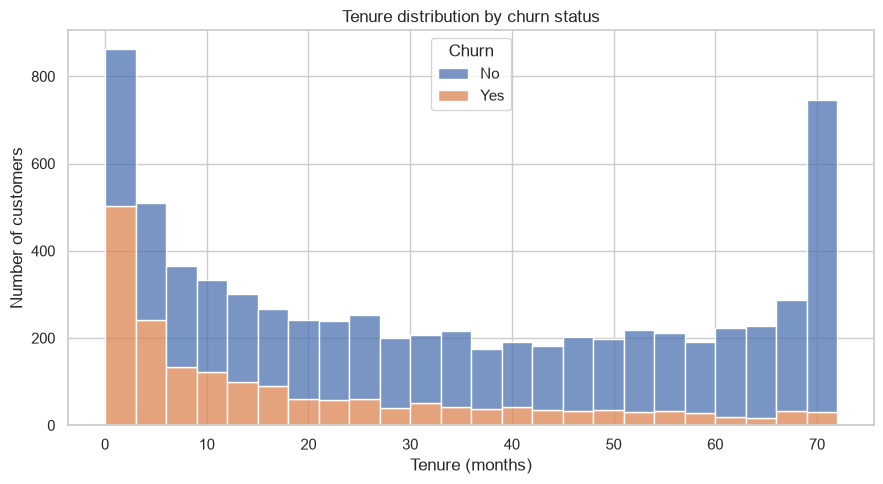

In [18]:
plt.figure(figsize=(9, 5))
sns.histplot(
    data=df,
    x="tenure",
    hue="Churn",
    bins=24,
    multiple="stack",
    kde=False
)
plt.title("Tenure distribution by churn status")
plt.xlabel("Tenure (months)")
plt.ylabel("Number of customers")
plt.tight_layout()
plt.show()

## 9. Multivariate analysis

### 9.1 Correlation among numerical variables

,tenure,MonthlyCharges,TotalCharges
tenure,1.000,0.248,0.826
MonthlyCharges,0.248,1.000,0.651
TotalCharges,0.826,0.651,1.000


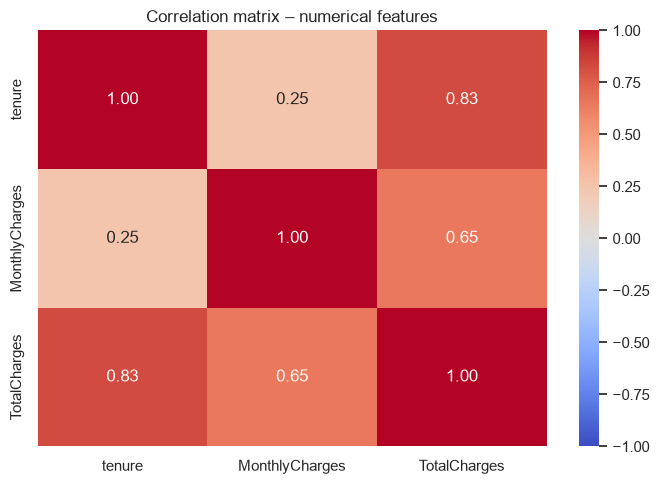

In [19]:
corr = df[numeric_cols].corr(numeric_only=True)
display(corr.round(3))

plt.figure(figsize=(7, 5))
sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f", vmin=-1, vmax=1)
plt.title("Correlation matrix – numerical features")
plt.tight_layout()
plt.show()

### 9.2 Pairwise relationships

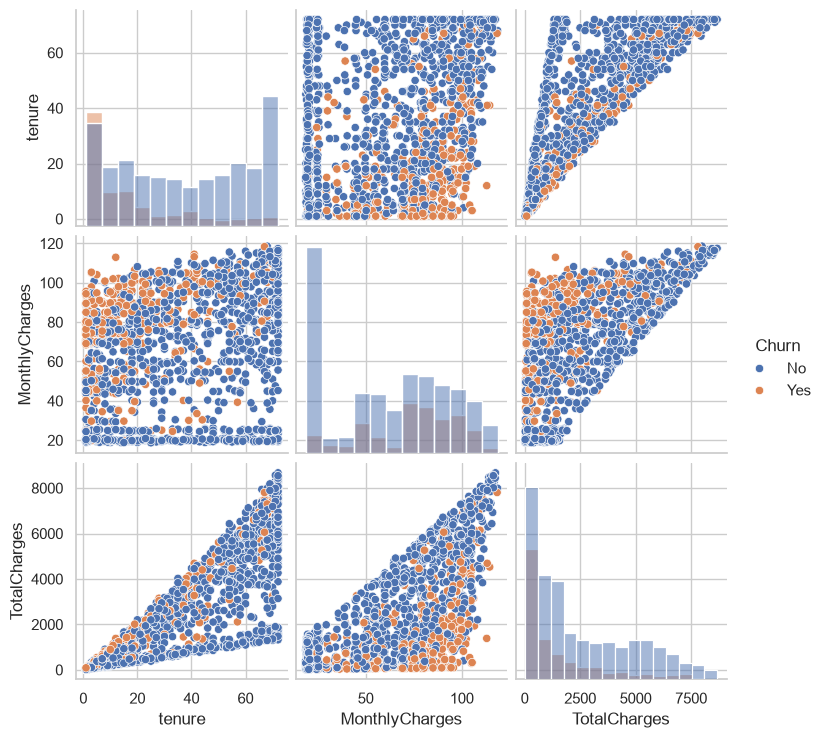

In [20]:
pairplot_data = df[numeric_cols + ["Churn"]].dropna()
sns.pairplot(
    pairplot_data.sample(min(1500, len(pairplot_data)), random_state=42),
    hue="Churn",
    diag_kind="hist"
)
plt.show()

### 9.3 Explore combinations of categorical features

In [21]:
# Example: contract type and internet service, split by churn
combo = pd.crosstab(
    [df["Contract"], df["InternetService"]],
    df["Churn"],
    normalize="index"
).mul(100)

display(combo.round(2))

Churn                              No    Yes
Contract       InternetService              
Month-to-month DSL              67.78  32.22
               Fiber optic      45.39  54.61
               No               81.11  18.89
One year       DSL              90.70   9.30
               Fiber optic      80.71  19.29
               No               97.53   2.47
Two year       DSL              98.09   1.91
               Fiber optic      92.77   7.23
               No               99.22   0.78

## 10. Outlier detection using IQR

In [22]:
outlier_results = []

for col in numeric_cols:
    values = df[col].dropna()
    q1 = values.quantile(0.25)
    q3 = values.quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    outlier_count = ((values < lower) | (values > upper)).sum()

    outlier_results.append({
        "feature": col,
        "Q1": q1,
        "Q3": q3,
        "IQR": iqr,
        "lower_bound": lower,
        "upper_bound": upper,
        "outlier_count": int(outlier_count),
        "outlier_percentage": outlier_count / len(values) * 100
    })

outlier_summary = pd.DataFrame(outlier_results).set_index("feature")
display(outlier_summary.round(2))

,Q1,Q3,IQR,lower_bound,upper_bound,outlier_count,outlier_percentage
feature,,,,,,,
tenure,9.00,55.00,46.00,-60.00,124.00,0,0.0
MonthlyCharges,35.50,89.85,54.35,-46.02,171.38,0,0.0
TotalCharges,401.45,3794.74,3393.29,-4688.48,8884.67,0,0.0


**Important:** IQR flags statistical extremes; it does not prove that a record is erroneous. Do not remove outliers without understanding the business meaning of the values.

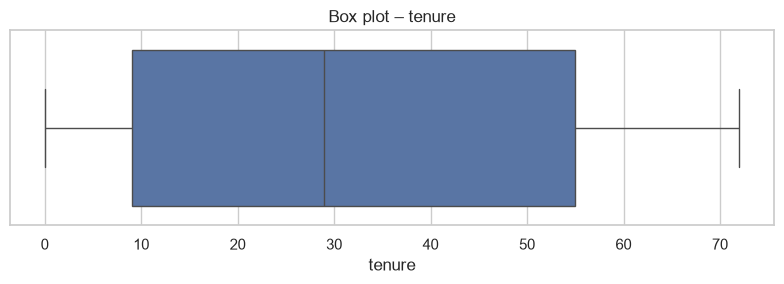

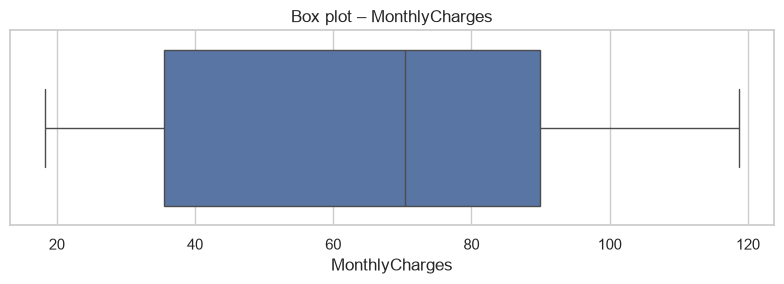

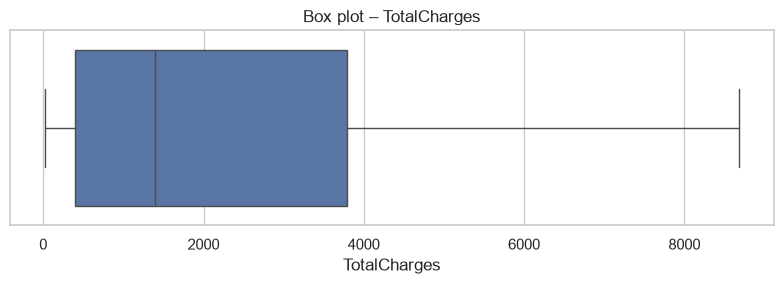

In [23]:
for col in numeric_cols:
    plt.figure(figsize=(8, 3))
    sns.boxplot(x=df[col])
    plt.title(f"Box plot – {col}")
    plt.tight_layout()
    plt.show()

## 11. Additional business-focused churn analysis

In [24]:
# Churn rates for selected features
selected_features = [
    "Contract", "PaymentMethod", "InternetService",
    "TechSupport", "OnlineSecurity", "SeniorCitizen",
    "Partner", "Dependents"
]

business_churn = {}
for col in selected_features:
    business_churn[col] = (
        df.groupby(col, dropna=False)["Churn"]
          .apply(lambda x: (x == "Yes").mean() * 100)
          .sort_values(ascending=False)
    )

for col, values in business_churn.items():
    print(f"\nChurn rate by {col} (%)")
    display(values.round(2).to_frame("churn_rate_percent"))


Churn rate by Contract (%)


,churn_rate_percent
Contract,
Month-to-month,42.71
One year,11.27
Two year,2.83



Churn rate by PaymentMethod (%)


,churn_rate_percent
PaymentMethod,
Electronic check,45.29
Mailed check,19.11
Bank transfer (automatic),16.71
Credit card (automatic),15.24



Churn rate by InternetService (%)


,churn_rate_percent
InternetService,
Fiber optic,41.89
DSL,18.96
No,7.40


... (6 outputs left out)


Churn rate by Partner (%)


,churn_rate_percent
Partner,
No,32.96
Yes,19.66



Churn rate by Dependents (%)


,churn_rate_percent
Dependents,
No,31.28
Yes,15.45


## 12. EDA findings – generate a data-driven summary

In [25]:
total_customers = len(df)
churn_rate = (df["Churn"].eq("Yes").mean() * 100)
print(f"Total customers: {total_customers:,}")
print(f"Overall churn rate: {churn_rate:.2f}%")

print("\\nAverage numerical values by churn:")
display(df.groupby("Churn")[numeric_cols].mean().round(2))

for col in ["Contract", "PaymentMethod", "InternetService", "TechSupport", "OnlineSecurity"]:
    rates = df.groupby(col)["Churn"].apply(lambda x: x.eq("Yes").mean() * 100)
    print(f"Highest churn category for {col}: {rates.idxmax()} ({rates.max():.2f}%)")

Total customers: 7,043
Overall churn rate: 26.54%
\nAverage numerical values by churn:


,tenure,MonthlyCharges,TotalCharges
Churn,,,
No,37.57,61.27,2555.34
Yes,17.98,74.44,1531.80


Highest churn category for Contract: Month-to-month (42.71%)
Highest churn category for PaymentMethod: Electronic check (45.29%)
Highest churn category for InternetService: Fiber optic (41.89%)
Highest churn category for TechSupport: No (41.64%)
Highest churn category for OnlineSecurity: No (41.77%)


## 13. Conclusions

Use the outputs above to write conclusions supported by the dataset. Questions to answer:

**Q. What percentage of customers churned?**

* **Answer:** 26.54%
* **Explanation:** Out of 7,043 customers, 1,869 customers churned, representing approximately 26.54% of the total customer base.

**Q. Which contract type has the highest churn rate?**

* **Answer:** Month-to-month -> 42.71% (churn = "Yes")
* **Explanation:** Among all contract types, month-to-month customers have the highest churn rate. Approximately 42.71% of customers with month-to-month contracts discontinued the service, indicating that customers with shorter-term commitments are more likely to churn compared to customers with one-year or two-year contracts.

**Q. How does tenure differ between churned and retained customers?**

* **Answer:** 
  - Churned customers (Yes) -> Average tenure: 17.98 months; Median: 10 months.
  - Retained customers (No) -> Average tenure: 37.57 months; Median: 38 months.

* **Explanation:** Customers who churned had significantly shorter tenure compared to retained customers. Churned customers stayed for an average of approximately 18 months, whereas retained customers stayed for approximately 38 months. This indicates that customers with shorter service tenure are more likely to churn, particularly during the early stages of their relationship with the company.

**Q. Which payment method is associated with the highest churn rate?**

* **Answer:** Electronic check -> 45.29% (churn = "Yes")
* **Explanation:** Customers using electronic checks have the highest churn rate (45.29%) compared to other payment methods. This indicates that customers paying through electronic checks are more likely to discontinue the service. Automatic payment methods, such as bank transfer and credit card, have considerably lower churn rates (16.71% and 15.24%, respectively).

**Q. Are monthly charges different between churn groups?**

* **Answer:** Yes. Churned customers (Yes) generally have higher monthly charges than retained customers (No).
* **Explanation:** The boxplot shows that customers who churned have a higher median monthly charge (approximately $79.95) compared to retained customers (approximately $64.45). This indicates that customers paying higher monthly charges are more likely to discontinue the service. However, this is an observed association and does not necessarily imply causation.

**Q. Which service-related categories show notable churn differences?**

* **Answer:**
  * **Internet Service:** Fiber optic users exhibit by far the highest churn rate (~41–42%), compared to DSL (~19%) and No Internet Service (~7%).
  * **Online Security & Tech Support:** Customers without these add-on protections churn at roughly 41–42%, whereas those with `OnlineSecurity` or `TechSupport` churn at only ~14–15%.
  * **Online Backup & Device Protection:** Customers lacking backup or device protection show churn rates around 39–40%, compared to ~21–23% for those subscribed to these services.
  * **Streaming Services (TV / Movies):** Customers without internet service churn the least (~7%), while those with streaming churn at roughly ~30–34% (largely driven by high fiber optic overlap).

* **Explanation:** The presence of core value-add support and security services acts as a strong retention anchor. Customers lacking `OnlineSecurity` and `TechSupport` are almost three times more likely to churn than those who subscribe to them. Additionally, `Fiber optic` users churn at an exceptionally high rate despite paying premium monthly fees, indicating potential pain points around service reliability, onboarding, or price sensitivity.

**Q. Which numerical variables are correlated?**

* **Answer:**
  * **tenure and TotalCharges:** Strong positive correlation ($r = 0.83$).
  * **MonthlyCharges and TotalCharges:** Moderate-to-strong positive correlation ($r = 0.65$).
  * **tenure and MonthlyCharges:** Weak positive correlation ($r = 0.25$).

* **Explanation:** All three numerical features exhibit positive linear relationships with one another, with the strongest association found between `tenure` and `TotalCharges` ($r = 0.83$). This makes intuitive domain sense, as total charges naturally accumulate over a longer customer tenure, while higher recurring monthly fees (`MonthlyCharges`) also contribute substantially to higher cumulative billings ($r = 0.65$). Conversely, `tenure` and `MonthlyCharges` show only a weak correlation ($r = 0.25$), indicating that a customer's monthly plan cost has very little direct bearing on how long they remain subscribed.

**Q. What data-quality issues need attention before modeling?**

* **Answer:**
  * **Blank / Whitespace Values in `TotalCharges`:** 11 records contain whitespace-only strings (`" "`), causing the column to be read as an `object` dtype rather than float.
  * **Zero Tenure Imputation / Edge Case:** All 11 blank `TotalCharges` entries correspond strictly to brand-new accounts with `tenure == 0`.
  * **Irrelevant Identifier Feature:** `customerID` is an arbitrary unique string that must be dropped prior to training to avoid data leakage or memorization.
  * **Redundant Categorical Levels:** Multiple service columns feature three levels (e.g., `Yes`, `No`, `No internet service` or `No phone service`), which represent overlapping domain states and need appropriate one-hot or ordinal encoding.
  * **Target Class Imbalance:** The target variable `Churn` is imbalanced (~73.5% `No` vs. ~26.5% `Yes`), which can skew model optimization toward the majority class.

* **Explanation:** As highlighted in Sections 5 of the notebook, `TotalCharges` must be coerced to a numeric type, creating `NaN` values that specifically represent customers who have not yet completed their first billing cycle (`tenure == 0`). These must either be imputed with `0.0` or dropped. Preprocessing must also drop non-predictive identifiers like `customerID`, structure categorical encodings to handle multi-level "No service" subcategories, and incorporate stratified splitting or class-weight adjustments to address the ~26.5% positive churn class.

**Reminder:** EDA is iterative. Revisit cleaning and feature definitions when visualizations or statistical summaries reveal unexpected values.

## Final outcome

EDA → Data Preprocessing → Feature Engineering → Machine Learning → Model Evaluation

The notebook prepares you for the next stage: building a Customer Churn Prediction Model using classification algorithms such as:

- Logistic Regression
- Decision Tree
- Random Forest
- XGBoost

Interview takeaway: EDA helps us understand the dataset, identify data-quality issues, discover patterns, test relationships, and make informed decisions before building a machine learning model.